# Vereisten

1. Lever één net en duidelijk gestructureerd notebook in.
2. Structureer het notebook met markdown cellen en nummer de hoofdstukken en paragraven.
3. Gebruik markdown cellen voor tekst en code cellen voor code.
4. Gebruik zoveel mogelijk zelf-gedefinieerde functies en bij voorkeur OOP.
5. De code voldoet aan PEP8 inclusief “comments”.
6. Alle groepsgenoten begrijpen alle code en de teksten die worden ingeleverd en zijn in staat deze toe te lichten als daarom wordt gevraagd.
7. Refereer voor zowel de tekst, de figuren en code op de juiste wijze aan gebruikte bronnen (zie bijlage 1)

In [107]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

df = pd.read_csv('train.csv', index_col='date_hour', parse_dates =['date_hour'])

# 1. EDA

Ieder teamlid maakt een account op Kaggle aan en vormt een team dat deelneemt
aan deze competitie: Voorspel verhuuraantallen 2026 | Kaggle
- Noteer je teamnaam, jullie namen en alle bijhorende Kaggle gebruikersnamen in het
notebook.
- Voer een Exploratieve Data Analyse (EDA) uit:
  1. Toon de datatypes en basisstatistieken van iedere kolom.
  2. Voeg tijdserie elementen toe en gebruik passende visualisaties om relevante patronen zichtbaar te maken.
  3. Onderzoek de relaties tussen de onafhankelijke variabelen enerzijds en de afhankelijke variabele anderzijds. Gebruik hierbij passende visualisaties.
  4. Beschrijf wat de belangrijkste bevindingen zijn van de EDA.
- Sommige regels en/of kolommen zijn soms niet relevant voor machine learning of bevatten onjuiste of missende waardes. Schoon, zo nodig, de data

## 1.1 Toon de datatypes en basisstatistieken van iedere kolom.

In [108]:
display(df.head())
display(df.info())
display(df.describe())
display(type(df.index))
display(f"Tijdspan: {df.index.min()} t/m {df.index.max()}")

,holiday,weathersit,temp,atemp,hum,windspeed,cnt
date_hour,,,,,,,
2011-01-01 00:00:00,0,1,0.24,0.2879,0.81,0.0,16
2011-01-01 01:00:00,0,1,0.22,0.2727,0.80,0.0,40
2011-01-01 02:00:00,0,1,0.22,0.2727,0.80,0.0,32
2011-01-01 03:00:00,0,1,0.24,0.2879,0.75,0.0,13
2011-01-01 04:00:00,0,1,0.24,0.2879,0.75,0.0,1


<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 16637 entries, 2011-01-01 00:00:00 to 2012-11-30 23:00:00
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   holiday     16637 non-null  int64  
 1   weathersit  16637 non-null  int64  
 2   temp        16637 non-null  float64
 3   atemp       16637 non-null  float64
 4   hum         16637 non-null  float64
 5   windspeed   16637 non-null  float64
 6   cnt         16637 non-null  int64  
dtypes: float64(4), int64(3)
memory usage: 1.0 MB


None

,holiday,weathersit,temp,atemp,hum,windspeed,cnt
count,16637.000000,16637.000000,16637.000000,16637.000000,16637.000000,16637.000000,16637.000000
mean,0.028671,1.415580,0.504745,0.482608,0.624756,0.190310,190.477009
std,0.166885,0.637298,0.192369,0.171557,0.193227,0.121915,182.026755
min,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,1.000000
25%,0.000000,1.000000,0.340000,0.333300,0.470000,0.104500,41.000000
50%,0.000000,1.000000,0.520000,0.500000,0.620000,0.194000,143.000000
75%,0.000000,2.000000,0.660000,0.621200,0.780000,0.253700,282.000000
max,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,977.000000


pandas.core.indexes.datetimes.DatetimeIndex

'Tijdspan: 2011-01-01 00:00:00 t/m 2012-11-30 23:00:00'

## 1.2. Nieuwe tijdseries toevoegen + passende visualisaties

In [109]:
df['year'] = df.index.year
df['month'] = df.index.month
df['day'] = df.index.day
df['hour'] = df.index.hour
df['day_of_week'] = df.index.dayofweek

display(df.head())

,holiday,weathersit,temp,atemp,hum,windspeed,cnt,year,month,day,hour,day_of_week
date_hour,,,,,,,,,,,,
2011-01-01 00:00:00,0,1,0.24,0.2879,0.81,0.0,16,2011,1,1,0,5
2011-01-01 01:00:00,0,1,0.22,0.2727,0.80,0.0,40,2011,1,1,1,5
2011-01-01 02:00:00,0,1,0.22,0.2727,0.80,0.0,32,2011,1,1,2,5
2011-01-01 03:00:00,0,1,0.24,0.2879,0.75,0.0,13,2011,1,1,3,5
2011-01-01 04:00:00,0,1,0.24,0.2879,0.75,0.0,1,2011,1,1,4,5


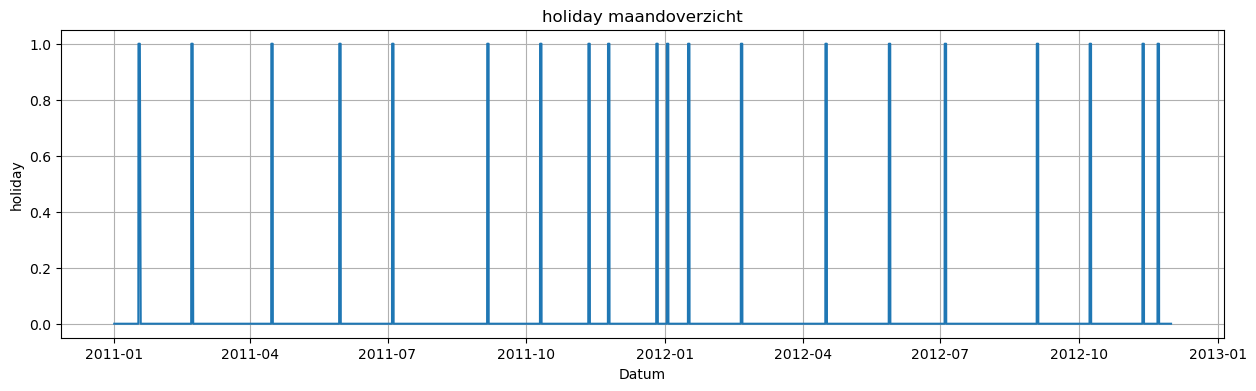

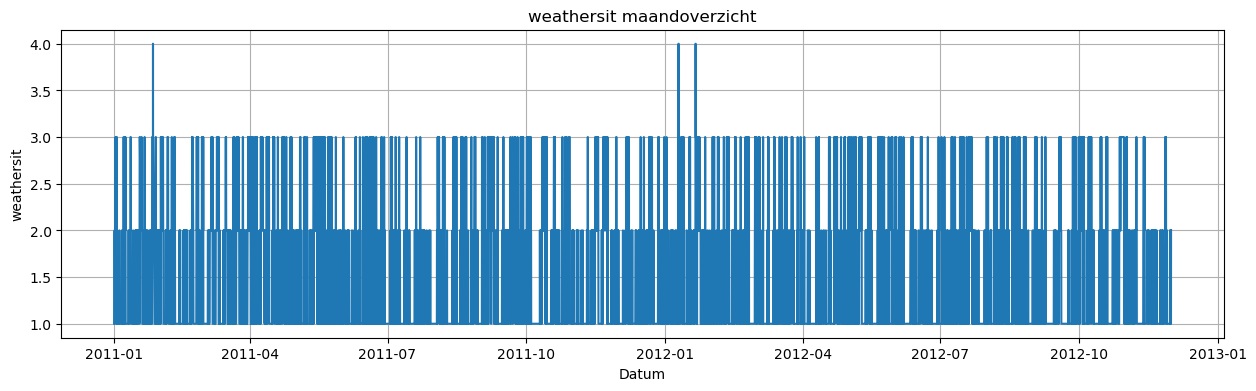

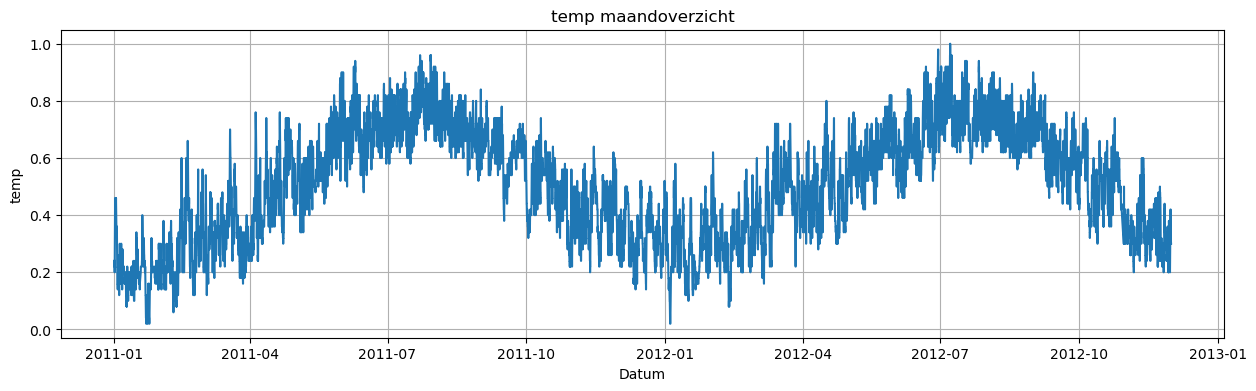

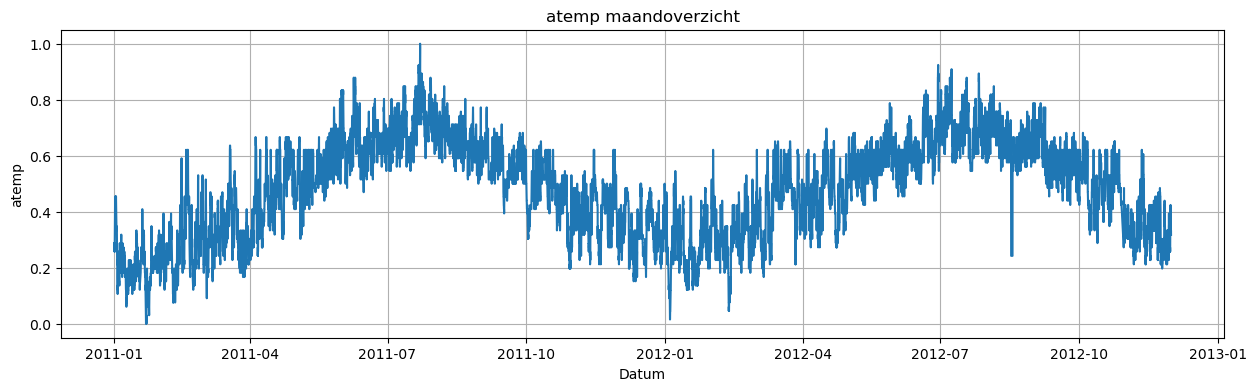

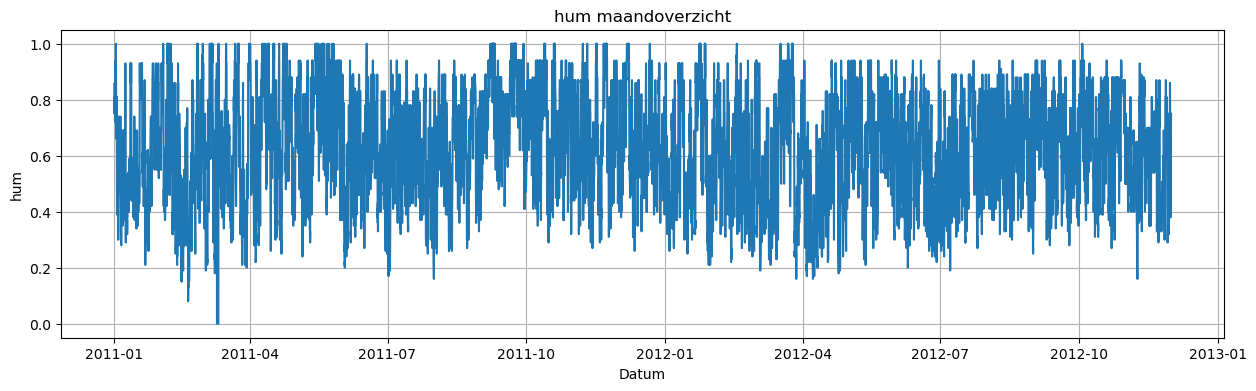

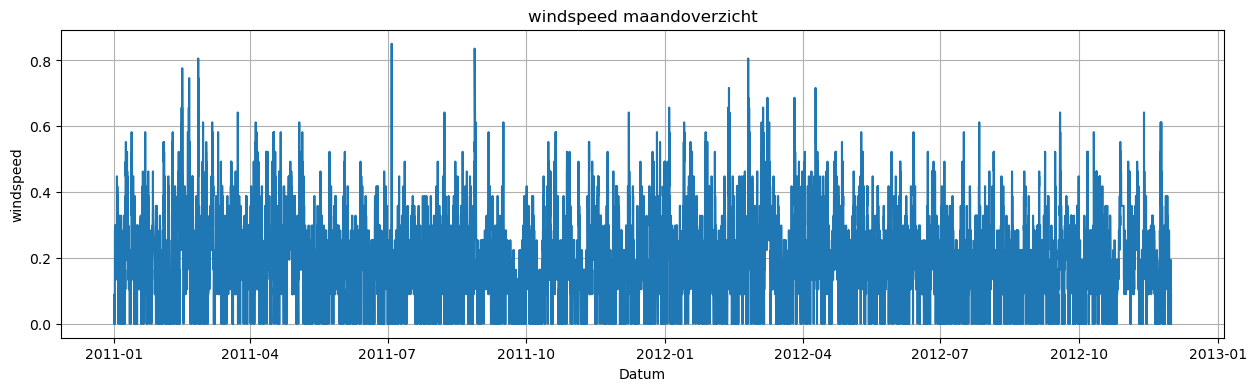

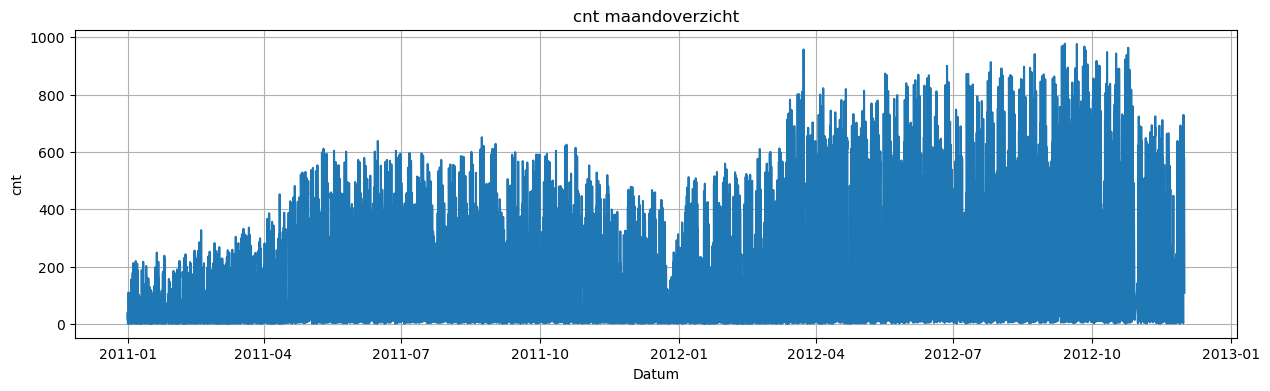

In [110]:
columns = ['holiday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'cnt']

for column in columns:
    plt.figure(figsize=(15, 4))
    plt.plot(df.index, df[column])
    plt.title(f'{column} maandoverzicht')
    plt.xlabel('Datum')
    plt.ylabel(column)
    plt.grid(True)
    plt.show()

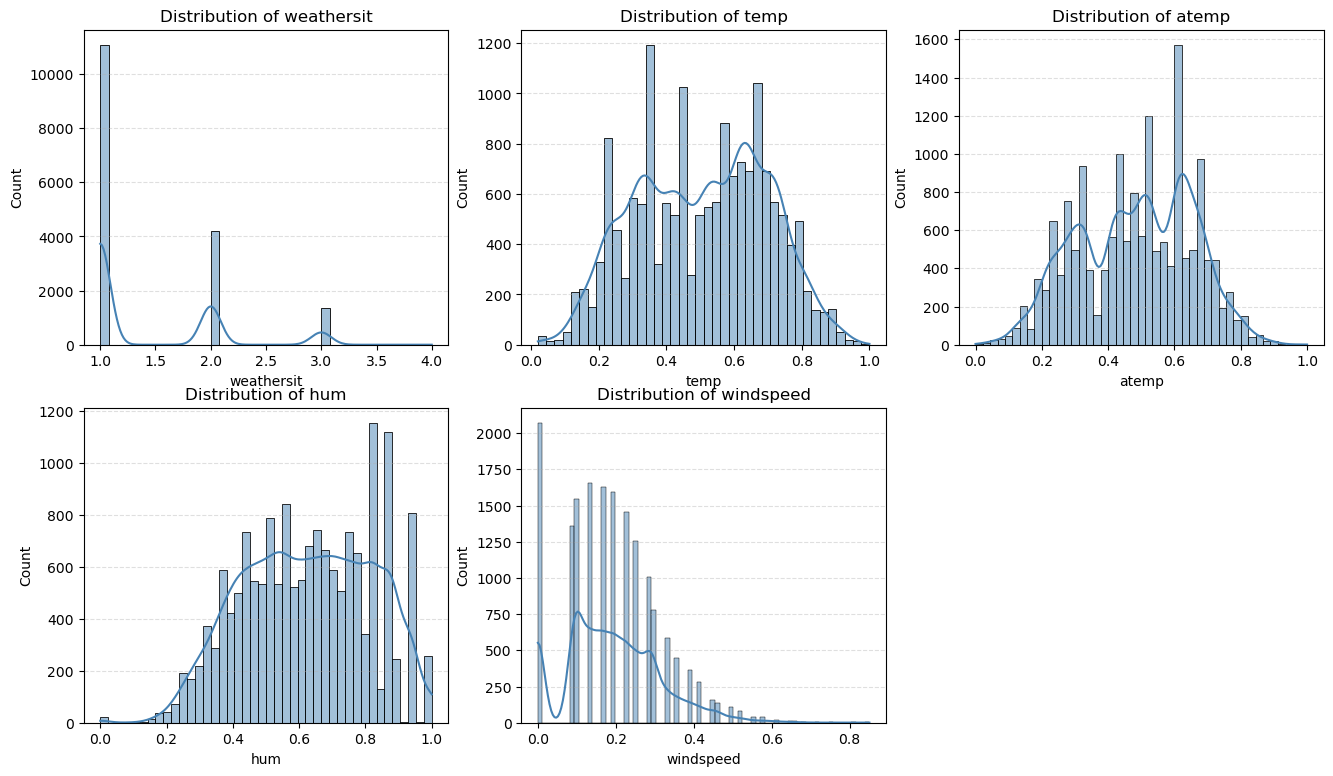

In [111]:
# Prompt: https://chatgpt.com/s/p_6b06b39c39948191b5d79e65246452d1


columns_hist = ['weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'cnt']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, column in enumerate(columns_hist):
    sns.histplot(
        data=df,
        x=column,
        kde=True,
        ax=axes[i],
        color='steelblue'
    )
    axes[i].set_title(f'Distribution of {column}')
    axes[i].grid(axis='y', linestyle='--', alpha=0.4)

axes[-1].set_visible(False)

## 1.3. Correlaties berekenen

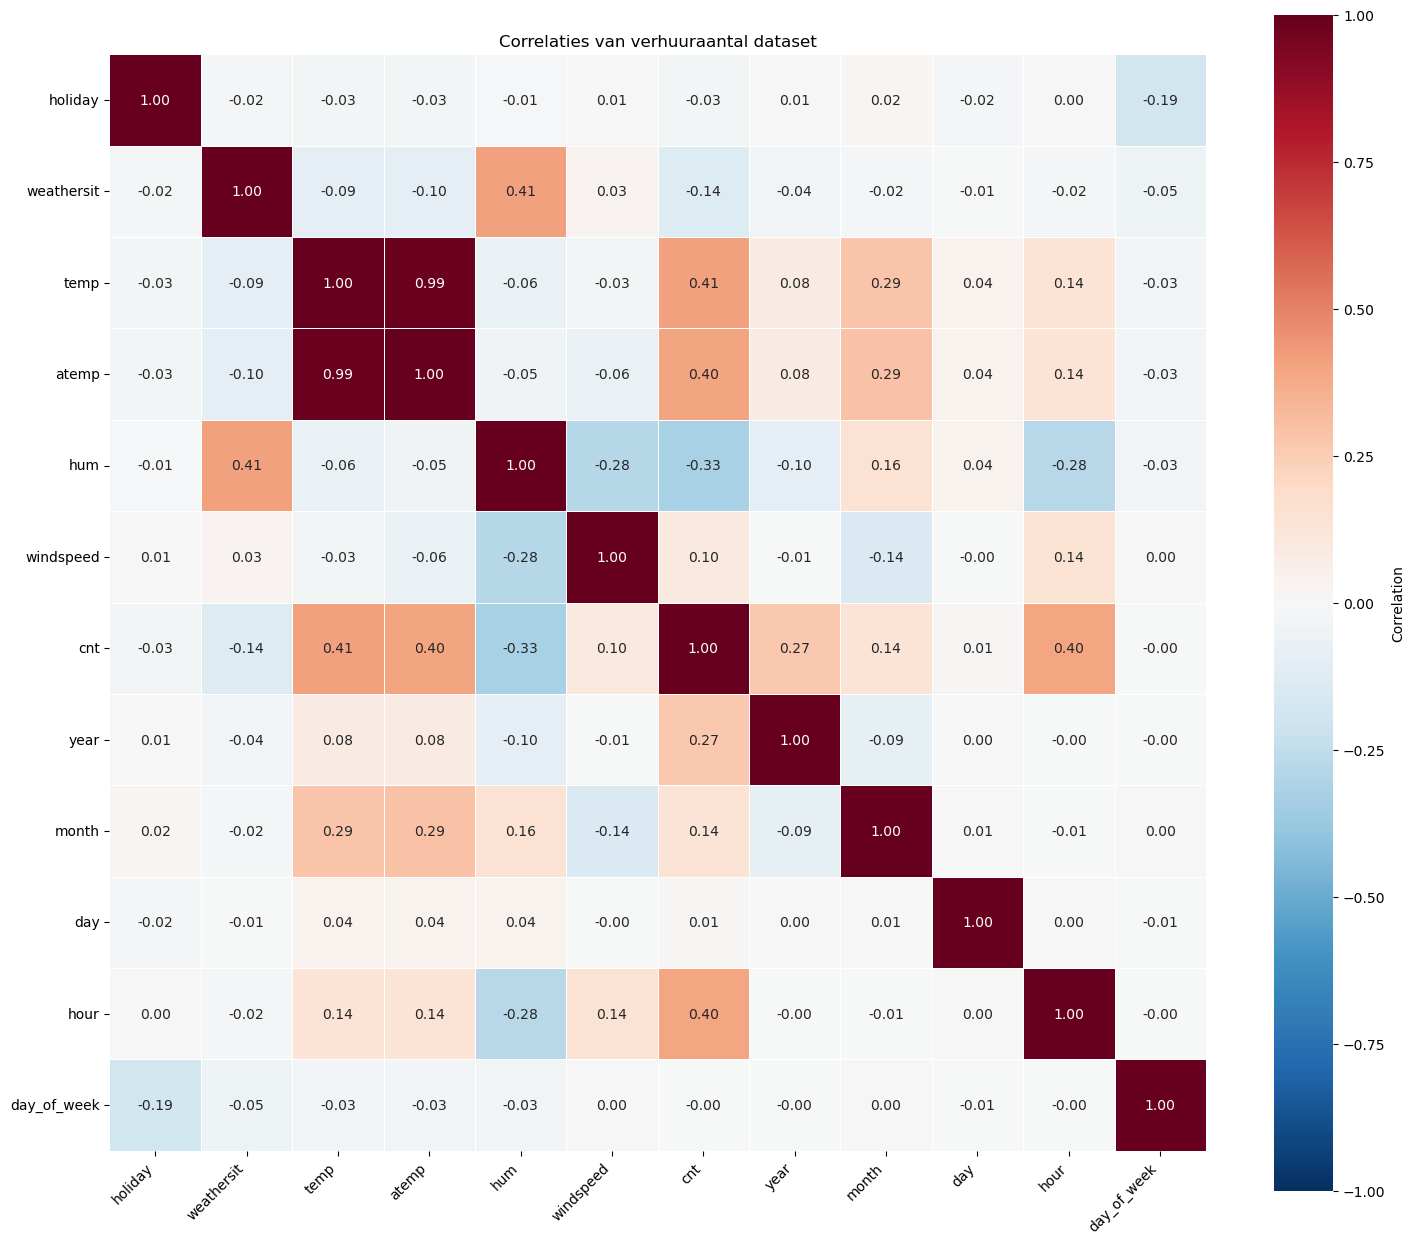

In [112]:
# Prompt: https://chatgpt.com/s/p_6b06af5a79748191a642ec768834e16f

correlations = df.corr()

plt.figure(figsize=(15, 15))

sns.heatmap(
    correlations,
    annot=True,               # Show correlation values
    fmt=".2f",                # Two decimal places
    cmap="RdBu_r",            # Red-blue diverging palette
    vmin=-1, vmax=1,          # Fixed correlation scale
    center=0,                 # Center palette at zero
    square=True,              # Square cells
    linewidths=0.5,           # Subtle cell borders
    linecolor="white",
    cbar_kws={"shrink": 0.8, "label": "Correlation"}
)

plt.title("Correlaties van verhuuraantal dataset")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.show()

# 1.4 Belangrijkste bevindingen EDA

**Data**
- De data heeft een tijdspan van 2011-01-01 - 2012-11-30, dus ongeveer 2 jaar.
- We hebben geen missende waarde in de dataset. 
- Alle gegevens los van cnt en weathersit lijkt genormaliseerd te zijn.
- Geen enkele gegeven lijkt normaal verdeeld te zijn.

**Visualisaties**
- **Holiday:** Er lijkt geen trend te zijn bij de holiday.
- **Weathersit:** Het is niet direct duidelijk wat voor mogelijke seizoenscomponenten uit Weather situation te halen zijn.
- **Temp:** Er lijk zowel een jaarlijks als dagelijks patroon te zijn binnen de dataset. Dit zou mogelijk iets te maken kunnen hebben met winter & zomer en dag & nacht.
- **Atemp:** Net zoals de gemeten temperatuur zou de daadwerkelijke temperatuur oop een jaarlijks en dagelijks patroon hebben.
- **hum:** Er lijken meerdere seizoenscomponenten te zijn. Dit zou verder onderzocht kunnen worden met behulp van de Fourier Transform.
- **windspeed:** Het is niet direct duidelijk of er een seizoenscomponent is. Dit zou verder onderzocht kunnen worden met behulp van de Fourier Transform.
- **cnt:** Er lijkt een algemene stijgende trend te zijn. Er is mogelijk een frequentie van 4 maanden aanwezig, maar dit zou pas later getest kunnen worden met de Fourier Transform.

**correlaties**
- cnt lijkt het meest te correleren met uur van de dag en temperatuur. Ondanks dit zou het handig zijn om bij het trainen van het model toch alle features mee te nemen.
- temperatuur is natuurlijk heel hoog gecorreleerd met actual temperatuur, daarom zou één van deze kolommen weg kunnen bij de voorspellingen. temp heeft net een hogere correlatie, dus atemp zal weggelaten worden.

# 1.5 Verwijder onjuiste of missende waarden

In [113]:
# Normalisering van weather situtation

df['weathersit'] = (df['weathersit'] - df['weathersit'].min()) /  (df['weathersit'].max() - df['weathersit'].min())
df = df.drop('atemp', axis=1)

In [114]:
display(df.describe())

,holiday,weathersit,temp,hum,windspeed,cnt,year,month,day,hour,day_of_week
count,16637.000000,16637.000000,16637.000000,16637.000000,16637.000000,16637.000000,16637.000000,16637.000000,16637.000000,16637.000000,16637.000000
mean,0.028671,0.138527,0.504745,0.624756,0.190310,190.477009,2011.480375,6.294164,15.670313,11.547875,3.008776
std,0.166885,0.212433,0.192369,0.193227,0.121915,182.026755,0.499630,3.310969,8.782122,6.914199,1.998538
min,0.000000,0.000000,0.020000,0.000000,0.000000,1.000000,2011.000000,1.000000,1.000000,0.000000,0.000000
25%,0.000000,0.000000,0.340000,0.470000,0.104500,41.000000,2011.000000,3.000000,8.000000,6.000000,1.000000
50%,0.000000,0.000000,0.520000,0.620000,0.194000,143.000000,2011.000000,6.000000,16.000000,12.000000,3.000000
75%,0.000000,0.333333,0.660000,0.780000,0.253700,282.000000,2012.000000,9.000000,23.000000,18.000000,5.000000
max,1.000000,1.000000,1.000000,1.000000,0.850700,977.000000,2012.000000,12.000000,31.000000,23.000000,6.000000


# 2. Time series feature engineerin

## 2.1. Voeg tijdserie features toe aan de dataset en onderzoek wat de invloed is van deze features, samen met de andere features, op de voorspellingen

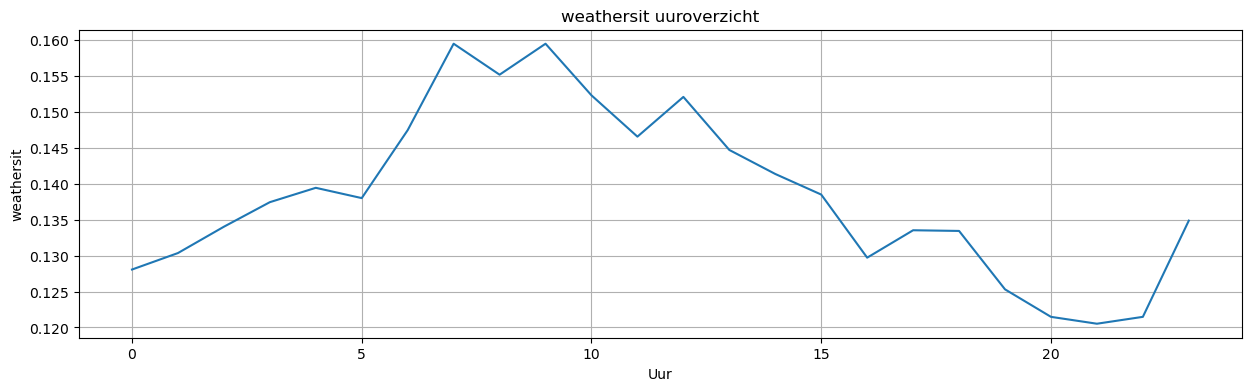

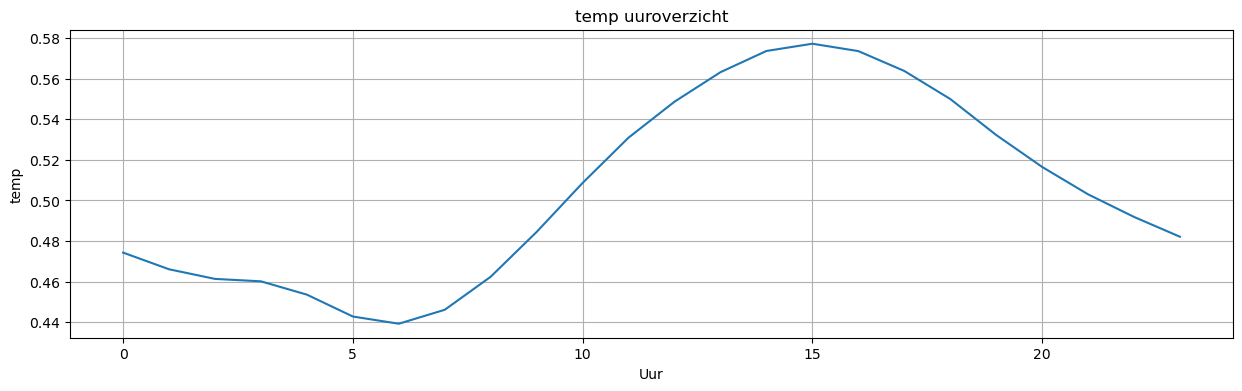

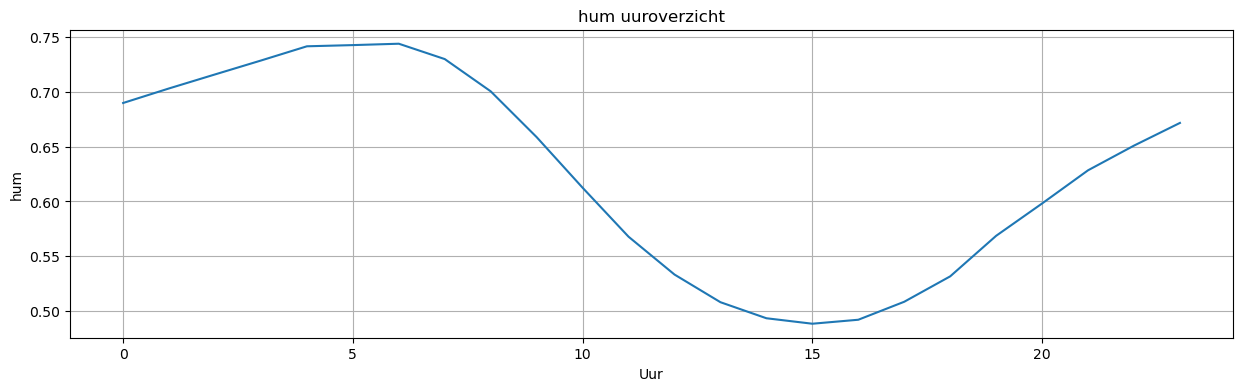

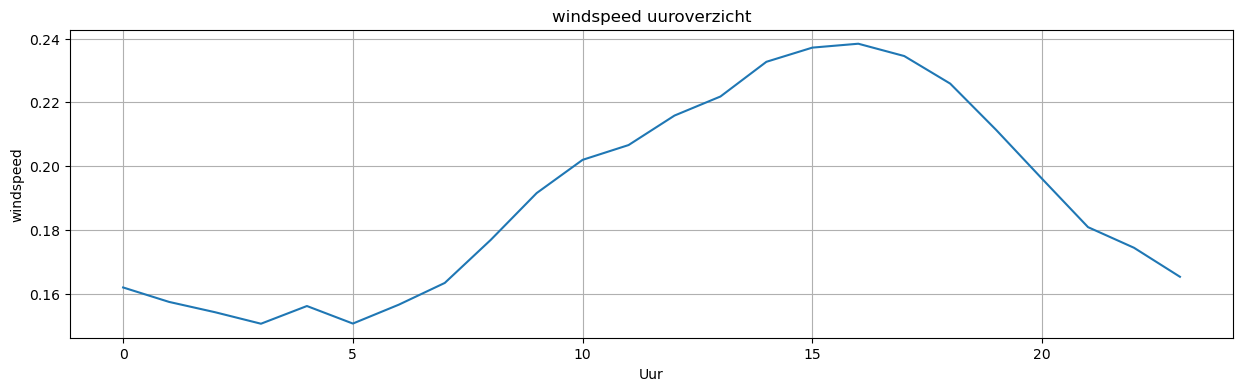

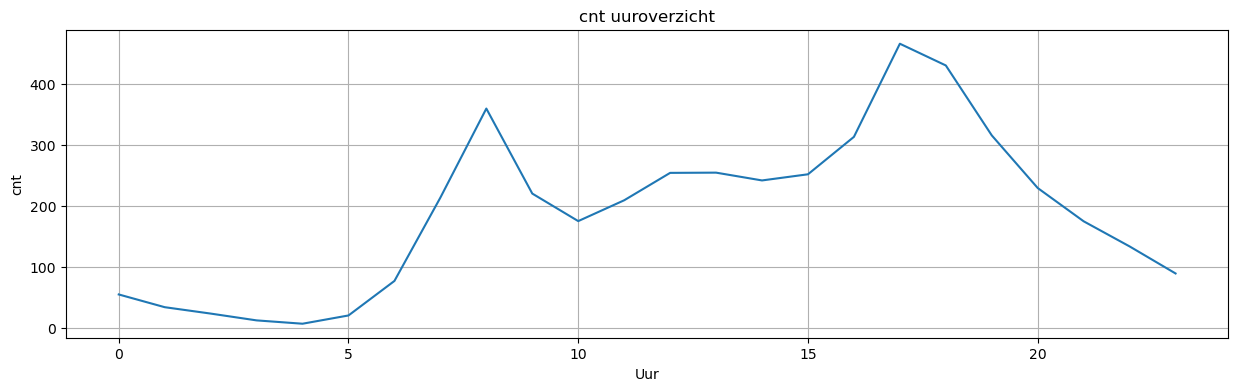

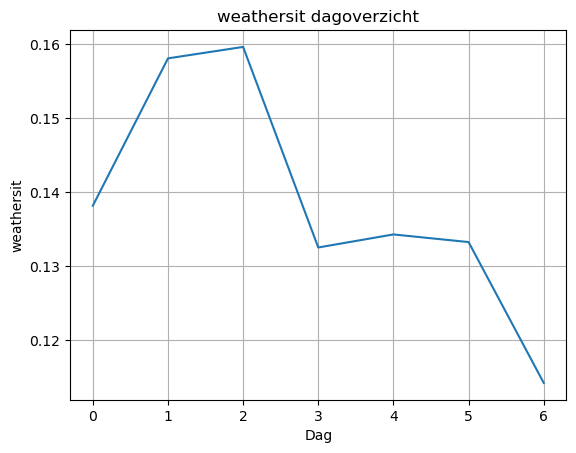

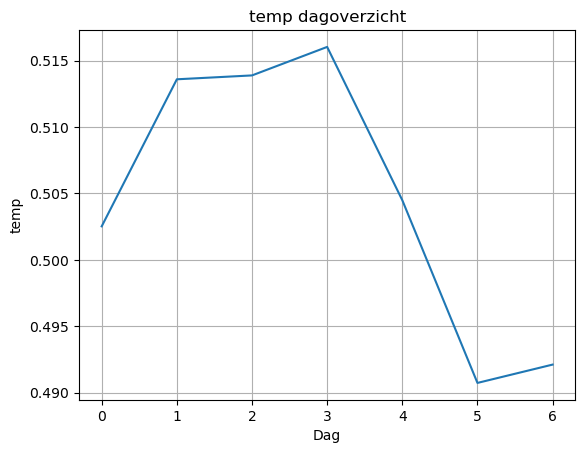

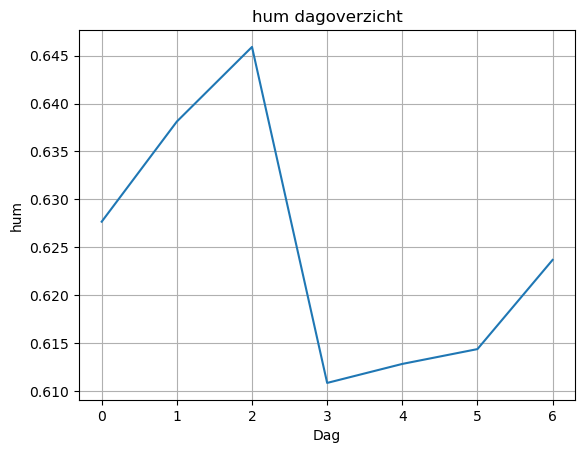

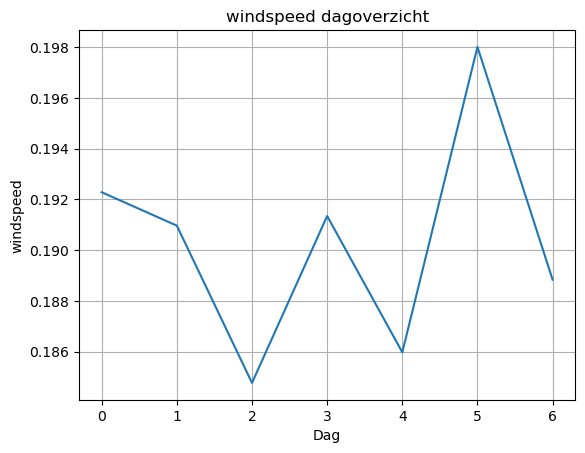

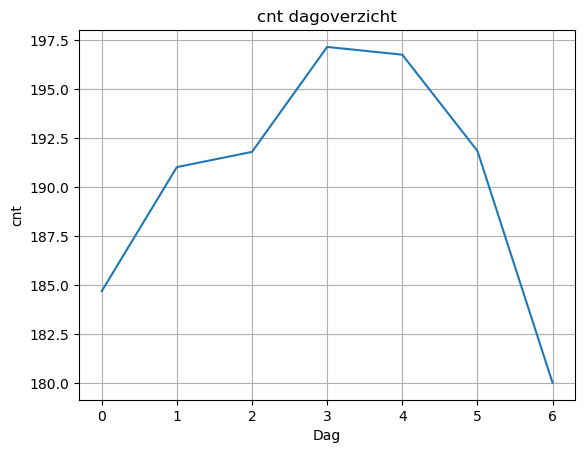

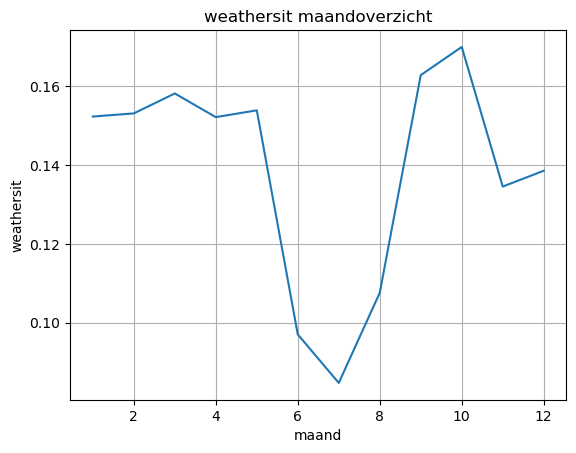

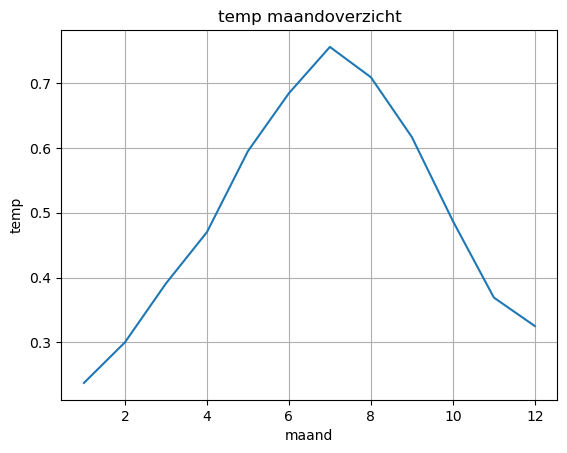

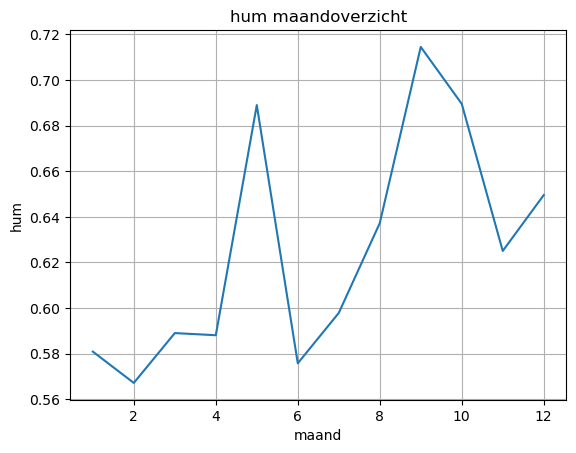

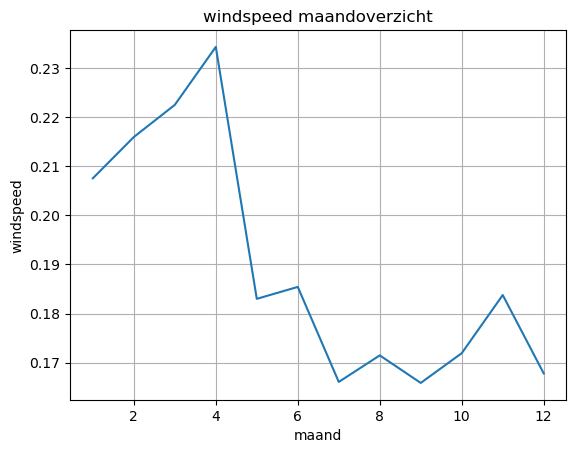

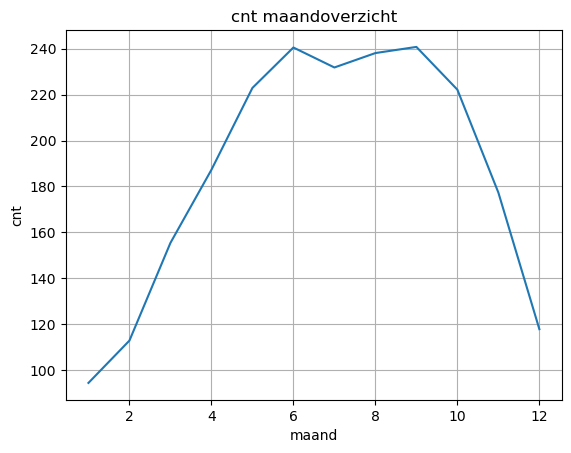

In [115]:
# Prompt: https://chatgpt.com/s/p_6b06b976b42c819193dec898c5055897

columns = ['holiday', 'weathersit', 'temp', 'hum', 'windspeed', 'cnt']

df_year = df.groupby('year')[columns].mean()
df_month = df.groupby('month')[columns].mean()
df_day = df.groupby('day')[columns].mean()
df_hour = df.groupby('hour')[columns].mean()
df_day_of_week = df.groupby('day_of_week')[columns].mean()

visualize_columns = ['weathersit', 'temp', 'hum', 'windspeed', 'cnt']

for column in visualize_columns:
    # Op uurbasis
    plt.figure(figsize=(15, 4))
    plt.plot(df_hour.index, df_hour[column])
    plt.title(f'{column} uuroverzicht')
    plt.xlabel('Uur')
    plt.ylabel(column)
    plt.grid(True)
    plt.show()

for column in visualize_columns:
    # Op dagbasis
    plt.plot(df_day_of_week.index, df_day_of_week[column])
    plt.title(f'{column} dagoverzicht')
    plt.xlabel('Dag')
    plt.ylabel(column)
    plt.grid(True)
    plt.show()

for column in visualize_columns:
    # Op maandbasis
    plt.plot(df_month.index, df_month[column])
    plt.title(f'{column} maandoverzicht')
    plt.xlabel('maand')
    plt.ylabel(column)
    plt.grid(True)
    plt.show()

#### Bevindingen

**Wel correlaties**
- Er lijkt bij humidity, windspeed en temperatuur een dagpatroon te zijn.
- Er lijkt een jaarpatroon te zijn bij cnt.

**Geen correlaties**
- Er lijkt geen patroon in weathersituation en holiday te zitten.

## 2.2. Onderzoek en uitleg van onderdelen




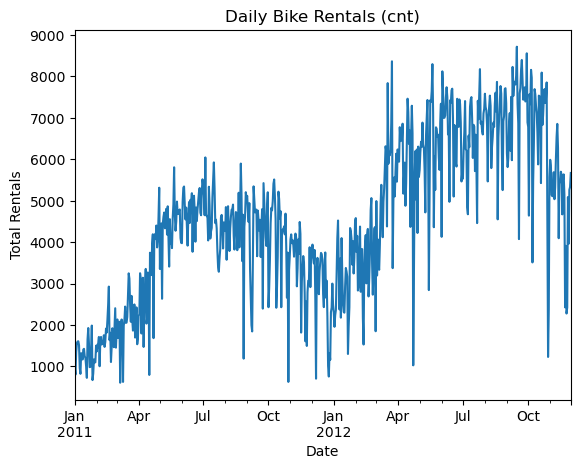

In [116]:
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

volledige_index = pd.date_range(df.index.min(), df.index.max(), freq='h')
cnt = df['cnt'].reindex(volledige_index).interpolate(method='time')

(df.head())

cnt.resample('D').sum().plot()
plt.title('Daily Bike Rentals (cnt)')
plt.ylabel('Total Rentals')
plt.xlabel('Date')
plt.show()

### 2.2.1. Fourier analyse

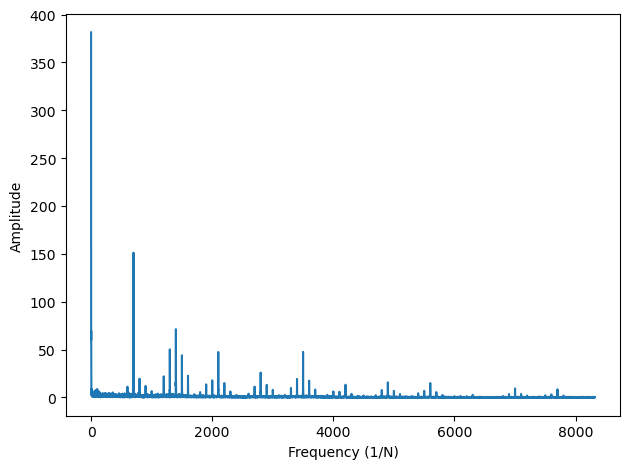

Peak bin index: 700
Peak frequency: 0.0417 cycles/hour
Cycle length:   24.00 hours


In [117]:
N = len(df)

df_ft = np.fft.fft(cnt)

magnitude = 2.0/N * np.abs(df_ft[:N//2])

plt.plot(magnitude)
plt.xlabel('Frequency (1/N)')
plt.ylabel('Amplitude')

plt.tight_layout()
plt.show()

centered_cnt = cnt - cnt.mean()

fft_vals = np.abs(np.fft.rfft(centered_cnt))
freqs = np.fft.rfftfreq(len(centered_cnt), d=1.0)

peak_idx = np.argmax(fft_vals)
peak_freq = freqs[peak_idx]
period_hours = 1 / peak_freq

print(f"Peak bin index: {peak_idx}")
print(f"Peak frequency: {peak_freq:.4f} cycles/hour")
print(f"Cycle length:   {period_hours:.2f} hours")

### 2.2.2. Trends


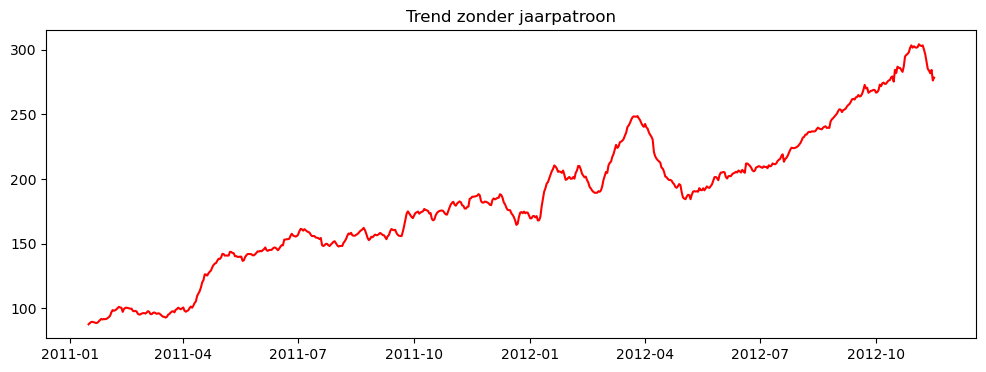

In [118]:
dag = seasonal_decompose(cnt, model='multiplicative', period = 24)
zonder_dag = cnt / dag.seasonal
#df['zonder dag'] = zonder_dag

week = seasonal_decompose(zonder_dag, model='multiplicative', period = 168)
zonder_dag_week = zonder_dag / week.seasonal

reeks = zonder_dag_week.dropna()

t = np.arange(len(reeks))
helling, intercept = np.polyfit(t, np.log(reeks.values), 1)
groei = pd.Series(np.exp(intercept + helling * t), index=reeks.index)

verhouding = reeks / groei

index_maand = verhouding.groupby(verhouding.index.month).mean()

index_maand = index_maand / index_maand.mean()

jaar_factor = reeks.index.month.map(index_maand)
zonder_jaar = reeks / np.asarray(jaar_factor)

dagelijks = zonder_jaar.resample('D').mean()

df['trend'] = dagelijks.rolling(30, center=True).mean()

plt.figure(figsize=(12, 4))
plt.plot(dagelijks.rolling(30, center=True).mean(), color='red', label='30 dagen')
plt.title('Trend zonder jaarpatroon')
plt.show()

### 2.2.3. Cicly en autocorrelatie

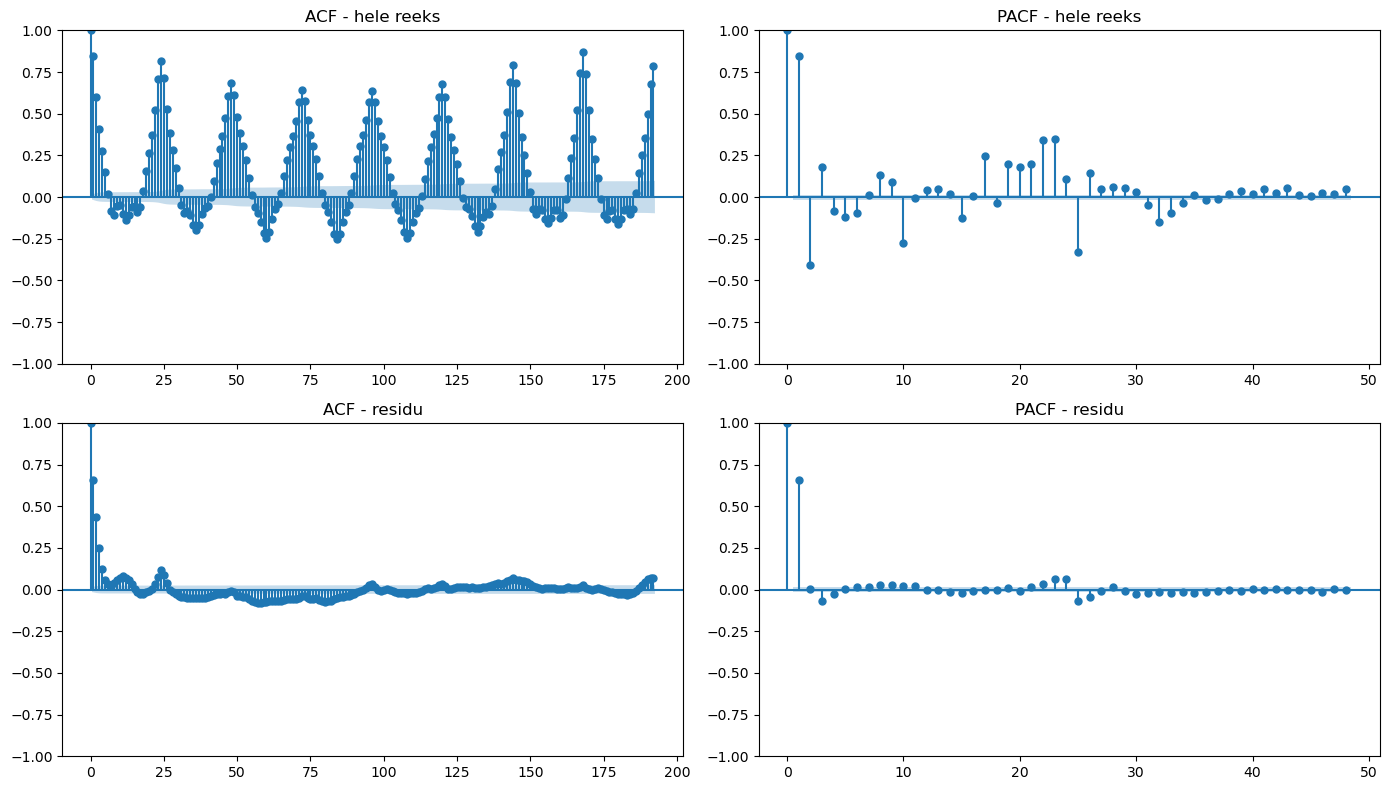

In [119]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

plot_acf(cnt, lags=24 * 8, ax=axes[0, 0], title='ACF - hele reeks')
plot_pacf(cnt, lags=48, ax=axes[0, 1], method='ywm', title='PACF - hele reeks')

residu = week.resid.dropna()
plot_acf(residu, lags=24 * 8, ax=axes[1, 0], title='ACF - residu')
plot_pacf(residu, lags=48, ax=axes[1, 1], method='ywm', title='PACF - residu')

plt.tight_layout()
plt.show()

### 2.2.4. andere tijdgebaseerde feature

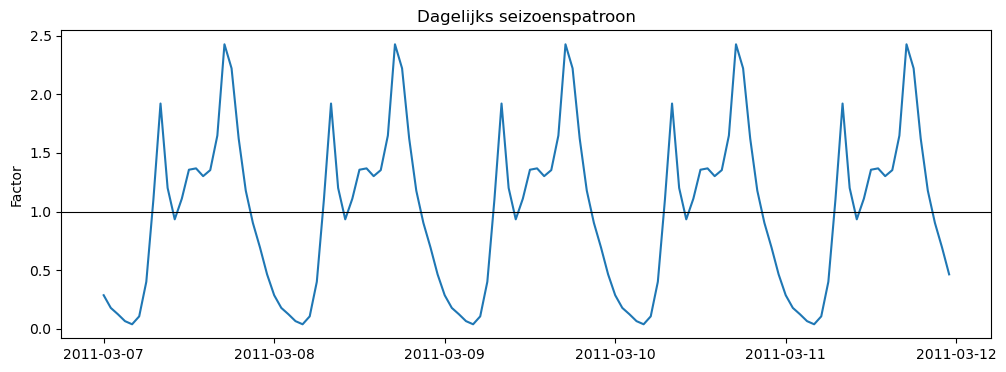

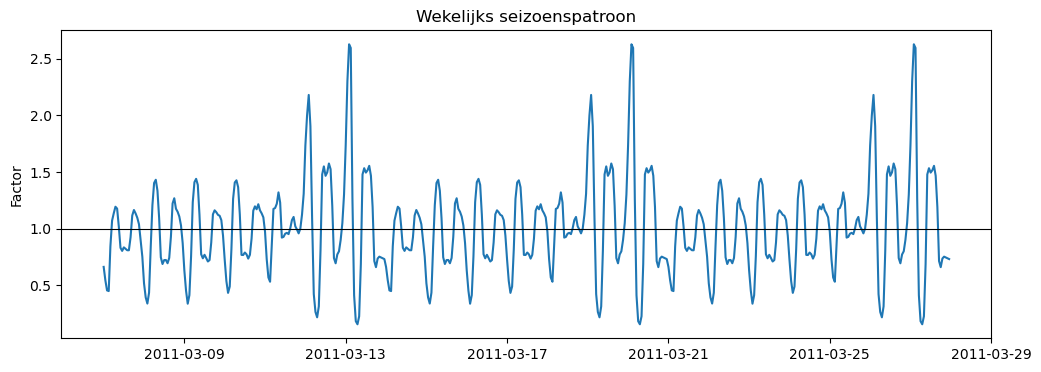

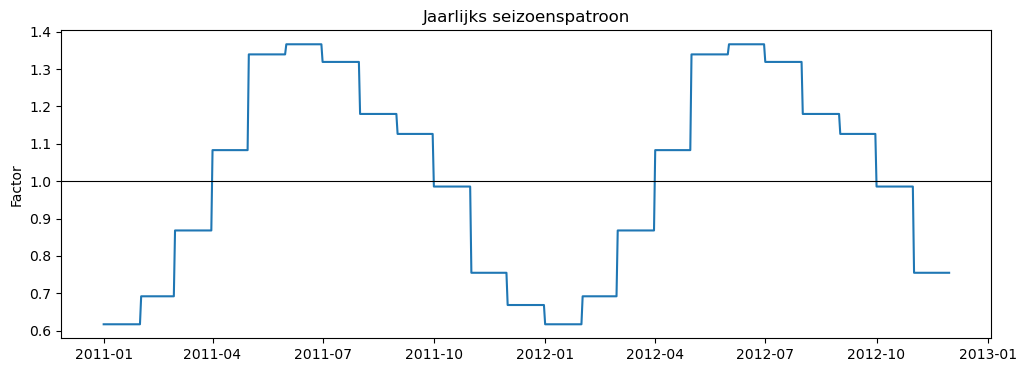

In [120]:
stuk_dag = dag.seasonal.loc['2011-03-07':'2011-03-11']

plt.figure(figsize=(12, 4))
plt.plot(stuk_dag)
plt.axhline(1, color='black', linewidth=0.8)
plt.title('Dagelijks seizoenspatroon')
plt.ylabel('Factor')
plt.show()

df['dag_patroon'] = dag.seasonal

stuk_week = week.seasonal.loc['2011-03-07':'2011-03-27']

plt.figure(figsize=(12, 4))
plt.plot(stuk_week)
plt.axhline(1, color='black', linewidth=0.8)
plt.title('Wekelijks seizoenspatroon')
plt.ylabel('Factor')
plt.show()

df['week_patroon'] = week.seasonal

jaar_patroon = pd.Series(np.asarray(jaar_factor), index=reeks.index)

plt.figure(figsize=(12, 4))
plt.plot(jaar_patroon.resample('D').mean())
plt.axhline(1, color='black', linewidth=0.8)
plt.title('Jaarlijks seizoenspatroon')
plt.ylabel('Factor')
plt.show()

df['jaar_patroon'] = jaar_patroon

## 3 Modelleren

### 3.1.1 Voorbereidingen

In [121]:
# 3.0 Voorbereiding: imports, data, features en cross-validation
from pathlib import Path

from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (HistGradientBoostingRegressor, RandomForestRegressor)
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
Path('submissions').mkdir(exist_ok=True)

# Ruwe data opnieuw inladen, zodat train en test exact dezelfde bewerkingen krijgen
train_raw = (pd.read_csv('train.csv', parse_dates=['date_hour'])
             .sort_values('date_hour').reset_index(drop=True))
test_raw = pd.read_csv('test.csv', parse_dates=['date_hour'])
sample = pd.read_csv('sample_submission.csv')
T0 = train_raw['date_hour'].min()

FOURIER = {'dag': (24, 3), 'week': (168, 3), 'jaar': (8766, 3)}  # (periode in uren, K)
WEER = ['temp', 'hum', 'windspeed']  # atemp laten we weg (zelfde keuze als in de EDA)


def fourier_kolommen():
    # Namen van alle sin/cos-kolommen
    return [f'{f}_{naam}_{k}' for naam, (_, n) in FOURIER.items()
            for k in range(1, n + 1) for f in ('sin', 'cos')]


def maak_features(data, t0=T0):
    # Voeg kalender-, trend- en Fourierfeatures toe (ook bruikbaar voor test)
    out = data.copy()
    ts = out['date_hour']
    out['hour'] = ts.dt.hour
    out['dayofweek'] = ts.dt.dayofweek
    out['month'] = ts.dt.month
    out['holiday'] = out['holiday'].astype(int)
    out['weathersit'] = out['weathersit'].astype(int)
    out['workingday'] = ((out['dayofweek'] < 5) & (out['holiday'] == 0)).astype(int)
    out['hour_workingday'] = out['workingday'].astype(str) + '_' + out['hour'].astype(str)
    uren = (ts - t0).dt.total_seconds() / 3600
    out['trend_days'] = uren / 24
    for naam, (periode, n) in FOURIER.items():
        for k in range(1, n + 1):
            hoek = 2 * np.pi * k * uren / periode
            out[f'sin_{naam}_{k}'] = np.sin(hoek)
            out[f'cos_{naam}_{k}'] = np.cos(hoek)
    return out


train = maak_features(train_raw)
test = maak_features(test_raw)

NUM_COLS = WEER + ['trend_days'] + fourier_kolommen()
CAT_COLS = ['weathersit', 'hour', 'dayofweek', 'month', 'holiday', 'workingday',
            'hour_workingday']
TREE_COLS = NUM_COLS + ['weathersit', 'hour', 'dayofweek', 'month', 'holiday', 'workingday']

X_train, y_train = train.drop(columns='cnt'), train['cnt']
X_test = test.copy()  # wordt pas bij het maken van de submissions gebruikt


def rmse(y_true, y_pred):
    # Beoordelingsmaat van de Kaggle-competitie
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))


def lineaire_prep():
    # Lineaire modellen: schaal numeriek, one-hot voor categorieën
    return ColumnTransformer([('num', StandardScaler(), NUM_COLS),
                              ('cat', OneHotEncoder(handle_unknown='ignore'), CAT_COLS)])


def boom_prep():
    # Boommodellen: geen schaling of one-hot nodig
    return ColumnTransformer([('num', 'passthrough', TREE_COLS)])


def maak_pipeline(prep, model):
    # Preprocessing + model in één pipeline
    return Pipeline([('prep', prep), ('model', model)])


# Cross-validation: 4 folds, elke validatie-fold is 19 dagen (= lengte van de test-set)
cv = TimeSeriesSplit(n_splits=4, test_size=19 * 24)
for i, (tr, va) in enumerate(cv.split(X_train), start=1):
    print(f"Fold {i}: train {train['date_hour'].iloc[tr[0]].date()} t/m "
          f"{train['date_hour'].iloc[tr[-1]].date()} | validatie "
          f"{train['date_hour'].iloc[va[0]].date()} t/m {train['date_hour'].iloc[va[-1]].date()}")

Fold 1: train 2011-01-01 t/m 2012-09-14 | validatie 2012-09-14 t/m 2012-10-03
Fold 2: train 2011-01-01 t/m 2012-10-03 | validatie 2012-10-03 t/m 2012-10-22
Fold 3: train 2011-01-01 t/m 2012-10-22 | validatie 2012-10-22 t/m 2012-11-11
Fold 4: train 2011-01-01 t/m 2012-11-11 | validatie 2012-11-11 t/m 2012-11-30


### 3.1.2 Functies

In [122]:
# 3.1 Hulpfuncties voor tunen en submissions
MODELLEN = {}        # naam -> ongetunede sklearn-pipeline
PARAM_GRIDS = {}     # naam -> hyperparameter-grid
RESULTATEN = {}      # naam -> CV-RMSE en beste parameters
SCHATTERS = {}       # naam -> getunede sklearn-schatter


def tune_model(naam):
    # Tune één model met GridSearchCV op de tijd-folds (alleen train-data)
    zoek = GridSearchCV(MODELLEN[naam], PARAM_GRIDS[naam], cv=cv, n_jobs=-1,
                        scoring='neg_root_mean_squared_error')
    zoek.fit(X_train, y_train)
    i = zoek.best_index_
    RESULTATEN[naam] = {'cv_rmse': -zoek.best_score_,
                        'cv_std': zoek.cv_results_['std_test_score'][i],
                        'beste_params': zoek.best_params_}
    SCHATTERS[naam] = zoek.best_estimator_  # al opnieuw gefit op alle train-data
    print(f"{naam}: CV-RMSE = {-zoek.best_score_:.2f} "
          f"(± {RESULTATEN[naam]['cv_std']:.2f})  {zoek.best_params_}")


def schrijf_submission(naam, voorspelling):
    # Schrijf csv in het formaat van sample_submission.csv
    voorspeld = pd.Series(voorspelling, index=test_raw['date_hour'].astype(str))
    uit = sample[['date_hour']].copy()
    uit['cnt'] = uit['date_hour'].map(voorspeld)
    assert uit['cnt'].notna().all(), f'{naam}: ontbrekende voorspellingen'
    bestandsnaam = naam.replace(' ', '_').replace('(', '').replace(')', '').replace('+', 'en')
    uit.to_csv(f'submissions/submission_{bestandsnaam}.csv', index=False)


def maak_submission(naam):
    # Voorspel de test-set met het getunede sklearn-model en schrijf de csv
    voorspelling = np.clip(SCHATTERS[naam].predict(X_test), 0, None)
    schrijf_submission(naam, voorspelling)

### 3.2.1 Linear regression

In [123]:
# 3.2 Lineaire regressie (OLS en Ridge)
MODELLEN['Lineaire regressie'] = maak_pipeline(lineaire_prep(), LinearRegression())
PARAM_GRIDS['Lineaire regressie'] = {}

MODELLEN['Ridge'] = maak_pipeline(lineaire_prep(), Ridge())
PARAM_GRIDS['Ridge'] = {'model__alpha': [0.1, 1, 10, 100, 1000]}

### 3.2.2 Random forest

In [124]:
# 3.3 Random Forest
MODELLEN['Random Forest'] = maak_pipeline(boom_prep(), RandomForestRegressor(
    n_estimators=150, n_jobs=-1, random_state=RANDOM_STATE))
PARAM_GRIDS['Random Forest'] = {'model__max_depth': [12, None],
                                'model__min_samples_leaf': [1, 5],
                                'model__max_features': [0.5, 1.0]}

### 3.2.3 XGBoost

In [125]:
# 3.4 XGBoost (installeren met: pip install xgboost)
from xgboost import XGBRegressor

MODELLEN['XGBoost'] = maak_pipeline(boom_prep(), XGBRegressor(
    tree_method='hist', n_jobs=1, random_state=RANDOM_STATE))
PARAM_GRIDS['XGBoost'] = {'model__n_estimators': [300, 600],
                          'model__learning_rate': [0.03, 0.1],
                          'model__max_depth': [4, 6],
                          'model__subsample': [0.8, 1.0]}

### 3.2.4 AdaBoost

In [126]:
# 3.5 AdaBoost
from sklearn.ensemble import AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor

MODELLEN['AdaBoost'] = maak_pipeline(boom_prep(), AdaBoostRegressor(
    estimator=DecisionTreeRegressor(random_state=RANDOM_STATE),
    random_state=RANDOM_STATE))
PARAM_GRIDS['AdaBoost'] = {'model__estimator__max_depth': [4, 8, 12],
                           'model__n_estimators': [100, 300],
                           'model__learning_rate': [0.1, 0.5]}

### 3.2.5 Gradient Boosting

In [127]:
# 3.6 Gradient Boosting
MODELLEN['Gradient Boosting'] = maak_pipeline(
    boom_prep(), HistGradientBoostingRegressor(random_state=RANDOM_STATE))
PARAM_GRIDS['Gradient Boosting'] = {'model__learning_rate': [0.03, 0.1],
                                    'model__max_leaf_nodes': [15, 31],
                                    'model__max_iter': [300, 600]}

### 3.2.6 Hybride Model

In [128]:
# 3.7 Hybride model: Ridge voorspelt, Gradient Boosting voorspelt de residuen daarvan
class HybridRegressor(BaseEstimator, RegressorMixin):

    def __init__(self, trend_model=None, residual_model=None, n_splits=5):
        self.trend_model = trend_model
        self.residual_model = residual_model
        self.n_splits = n_splits

    def fit(self, X, y):
        y = pd.Series(np.asarray(y), index=X.index)
        # Out-of-fold voorspellingen, zodat de residuen niet te klein zijn (geen lekkage)
        oof = np.zeros(len(y))
        for tr, va in KFold(self.n_splits, shuffle=True, random_state=RANDOM_STATE).split(X):
            oof[va] = clone(self.trend_model).fit(X.iloc[tr], y.iloc[tr]).predict(X.iloc[va])
        self.trend_model_ = clone(self.trend_model).fit(X, y)
        self.residual_model_ = clone(self.residual_model).fit(X, y.to_numpy() - oof)
        return self

    def predict(self, X):
        return self.trend_model_.predict(X) + self.residual_model_.predict(X)


MODELLEN['Hybride (Ridge + GB)'] = HybridRegressor(
    trend_model=maak_pipeline(lineaire_prep(), Ridge(alpha=10)),
    residual_model=maak_pipeline(boom_prep(), HistGradientBoostingRegressor(
        random_state=RANDOM_STATE)))
PARAM_GRIDS['Hybride (Ridge + GB)'] = {
    'trend_model__model__alpha': [1, 10, 100],
    'residual_model__model__learning_rate': [0.03, 0.1],
    'residual_model__model__max_iter': [200, 400]}

### 3.2.7 SARIMAX

In [129]:
# 3.8 SARIMAX (regressie met ARIMA-fouten) + voorbereiding voor de tijdseriemodellen
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX


def maak_uur_frame():
    # Complete uurlijkse tijdas (train + test); ontbrekende uren krijgen cnt = NaN
    kolommen = ['date_hour', 'holiday', 'weathersit'] + WEER
    alles = pd.concat([train_raw[kolommen + ['cnt']], test_raw[kolommen]], ignore_index=True)
    alles = alles.set_index('date_hour').sort_index()
    alles = alles.reindex(pd.date_range(alles.index.min(), alles.index.max(), freq='h'))
    alles.index.name = 'date_hour'
    alles[WEER] = alles[WEER].interpolate(limit_direction='both')
    alles[['holiday', 'weathersit']] = alles[['holiday', 'weathersit']].ffill().bfill()
    return maak_features(alles.reset_index()).set_index('date_hour').asfreq('h')


uur = maak_uur_frame()


def sarimax_exog(frame):
    # Exogene variabelen: weer, werkdag, trend, dagpatroon (apart voor werkdag/vrij), jaarpatroon
    exog = pd.DataFrame(index=frame.index)
    exog['trend_jaren'] = frame['trend_days'] / 365.25
    for kolom in ['temp', 'hum', 'windspeed', 'workingday']:
        exog[kolom] = frame[kolom]
    exog['weer_2'] = (frame['weathersit'] == 2).astype(float)
    exog['weer_3plus'] = (frame['weathersit'] >= 3).astype(float)
    for k in range(1, FOURIER['dag'][1] + 1):
        for f in ('sin', 'cos'):
            exog[f'{f}_dag_{k}_werkdag'] = frame[f'{f}_dag_{k}'] * frame['workingday']
            exog[f'{f}_dag_{k}_vrij'] = frame[f'{f}_dag_{k}'] * (1 - frame['workingday'])
    for kolom in fourier_kolommen():
        if '_jaar_' in kolom:
            exog[kolom] = frame[kolom]
    return exog.astype(float)


def sarimax_forecast(frame, start, eind, order, seasonal_order):
    # Fit op alle uren vóór positie `start`, voorspel de uren start t/m eind
    start, eind = int(start), int(eind)  # statsmodels verwacht gewone ints, geen numpy-ints
    exog = sarimax_exog(frame)
    model = SARIMAX(frame['cnt'].iloc[:start], exog=exog.iloc[:start], order=order,
                    seasonal_order=seasonal_order, trend='c',
                    enforce_stationarity=False, enforce_invertibility=False)
    resultaat = model.fit(disp=False, maxiter=50)
    fc = resultaat.forecast(steps=eind - start, exog=exog.iloc[start:eind])
    return pd.Series(np.asarray(fc), index=frame.index[start:eind])


def cv_tijdserie(forecast_fn, **config):
    # Gemiddelde RMSE van een tijdseriemodel over dezelfde TimeSeriesSplit-folds
    scores = []
    for _, val_idx in cv.split(X_train):
        start = train['date_hour'].iloc[val_idx[0]]
        eind = train['date_hour'].iloc[val_idx[-1]] + pd.Timedelta(hours=1)
        s = uur.index.searchsorted(start)
        e = uur.index.searchsorted(eind)
        fc = forecast_fn(uur, s, e, **config).to_numpy()
        echt = uur['cnt'].iloc[s:e].to_numpy()
        geldig = ~np.isnan(echt)  # alleen uren die echt waargenomen zijn
        scores.append(rmse(echt[geldig], np.clip(fc[geldig], 0, None)))
    return float(np.mean(scores)), float(np.std(scores))


TS_MODELLEN = {}  # naam -> (forecast-functie, lijst met configuraties om te proberen)


def tune_tijdserie(naam):
    # Kies de beste configuratie op de tijd-folds (alleen train-data)
    forecast_fn, configs = TS_MODELLEN[naam]
    beste = None
    for config in configs:
        gem, std = cv_tijdserie(forecast_fn, **config)
        print(f'{naam} {config}: CV-RMSE = {gem:.2f} (± {std:.2f})')
        if beste is None or gem < beste[0]:
            beste = (gem, std, config)
    RESULTATEN[naam] = {'cv_rmse': beste[0], 'cv_std': beste[1], 'beste_params': beste[2]}


def maak_submission_tijdserie(naam):
    # Fit op alle train-data, voorspel de test-periode en schrijf de csv
    forecast_fn, _ = TS_MODELLEN[naam]
    s = uur.index.searchsorted(test_raw['date_hour'].min())
    fc = forecast_fn(uur, s, len(uur), **RESULTATEN[naam]['beste_params'])
    schrijf_submission(naam, np.clip(fc.reindex(test_raw['date_hour']).to_numpy(), 0, None))


TS_MODELLEN['SARIMAX'] = (sarimax_forecast, [
    {'order': (1, 0, 0), 'seasonal_order': (0, 0, 0, 0)},
    {'order': (2, 0, 1), 'seasonal_order': (0, 0, 0, 0)},
    {'order': (1, 0, 0), 'seasonal_order': (1, 0, 0, 24)},
])

### 3.2.8 Holt Winters

In [130]:
# 3.9 Holt-Winters (exponentiële afvlakking, weekseizoen van 168 uur)
def holt_winters_forecast(frame, start, eind, trend, damped):
    # Fit op alle uren vóór positie `start`, voorspel de uren start t/m eind
    start, eind = int(start), int(eind)  # statsmodels verwacht gewone ints, geen numpy-ints
    historie = frame['cnt'].iloc[:start].interpolate(limit_direction='both')
    model = ExponentialSmoothing(historie.to_numpy(), trend=trend, damped_trend=damped,
                                 seasonal='add', seasonal_periods=168,
                                 initialization_method='heuristic')
    fc = model.fit().forecast(eind - start)
    return pd.Series(np.asarray(fc), index=frame.index[start:eind])


TS_MODELLEN['Holt-Winters'] = (holt_winters_forecast, [
    {'trend': None, 'damped': False},
    {'trend': 'add', 'damped': False},
    {'trend': 'add', 'damped': True},
])

### 3.3 Tuning

In [134]:
# 3.10 Tunen: gebruikt alleen train.csv. Haal het # weg bij de modellen die je wilt tunen.
tune_model('Lineaire regressie')
tune_model('Ridge')
tune_model('Random Forest')
tune_model('XGBoost')
tune_model('AdaBoost')
tune_model('Gradient Boosting')
tune_model('Hybride (Ridge + GB)')
#tune_tijdserie('SARIMAX')
#tune_tijdserie('Holt-Winters')

# Of alle sklearn-modellen in één keer:
# for naam in MODELLEN:
#     tune_model(naam)

Lineaire regressie: CV-RMSE = 101.47 (± 15.21)  {}
Ridge: CV-RMSE = 101.46 (± 15.22)  {'model__alpha': 0.1}
Random Forest: CV-RMSE = 66.29 (± 9.85)  {'model__max_depth': None, 'model__max_features': 0.5, 'model__min_samples_leaf': 1}
XGBoost: CV-RMSE = 63.15 (± 8.69)  {'model__learning_rate': 0.1, 'model__max_depth': 6, 'model__n_estimators': 600, 'model__subsample': 0.8}
AdaBoost: CV-RMSE = 72.27 (± 15.14)  {'model__estimator__max_depth': 12, 'model__learning_rate': 0.5, 'model__n_estimators': 100}
Gradient Boosting: CV-RMSE = 62.05 (± 8.09)  {'model__learning_rate': 0.1, 'model__max_iter': 600, 'model__max_leaf_nodes': 31}
Hybride (Ridge + GB): CV-RMSE = 60.54 (± 4.29)  {'residual_model__model__learning_rate': 0.1, 'residual_model__model__max_iter': 400, 'trend_model__model__alpha': 1}


### 3.4 Submissions

In [137]:
# 3.11 Submissions maken (pas uitvoeren als je klaar bent met tunen)
#maak_submission('Ridge')
maak_submission('Random Forest')
maak_submission('XGBoost')
maak_submission('AdaBoost')
maak_submission('Gradient Boosting')
maak_submission('Hybride (Ridge + GB)')
maak_submission_tijdserie('SARIMAX')
maak_submission_tijdserie('Holt-Winters')

# Of alle getunede sklearn-modellen in één keer:
# for naam in SCHATTERS:
#     maak_submission(naam)

c:\Users\samde\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


### 3.5 Overzicht van modellen

In [135]:
# 3.12 Overzicht van alle getunede modellen
overzicht = (pd.DataFrame(RESULTATEN).T
             .astype({'cv_rmse': float, 'cv_std': float})
             .sort_values('cv_rmse'))
display(overzicht.round(2))

,cv_rmse,cv_std,beste_params
Hybride (Ridge + GB),60.54,4.29,"{'residual_model__model__learning_rate': 0.1, ..."
Gradient Boosting,62.05,8.09,"{'model__learning_rate': 0.1, 'model__max_iter..."
XGBoost,63.15,8.69,"{'model__learning_rate': 0.1, 'model__max_dept..."
Random Forest,66.29,9.85,"{'model__max_depth': None, 'model__max_feature..."
AdaBoost,72.27,15.14,"{'model__estimator__max_depth': 12, 'model__le..."
Ridge,101.46,15.22,{'model__alpha': 0.1}
Lineaire regressie,101.47,15.21,{}
SARIMAX,121.84,15.48,"{'order': (1, 0, 0), 'seasonal_order': (1, 0, ..."
Holt-Winters,126.30,27.90,"{'trend': None, 'damped': False}"


# AI bronvermelding
- ChatGPT. 2026. https://chatgpt.com/share/6b06af13-52dc-83eb-af9b-83878dc183c7
- Claude. 2026. https://claude.ai/share/abbbf6a5-1539-4cb5-8d8b-a6199b48fae0